# HW7
## Metro Interstate Traffic Volume

**Dataset:** Metro Interstate Traffic Volume  
**Source:** UCI Machine Learning Repository  
**Dataset page:** https://archive.ics.uci.edu/dataset/492/metro+interstate+traffic+volume  


The dataset contains hourly westbound I-94 traffic volume near Minneapolis–St. Paul, Minnesota, together with weather and holiday variables from 2012–2018.




## 1. Imports

The notebook uses Pandas, NumPy, Matplotlib, Seaborn, and `ipywidgets`, all of which are available in standard Google Colab environments.


In [ ]:
import io
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
from ipywidgets import interact

try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)


## 2. Load the data

`Metro_Interstate_Traffic_Volume.csv` needs to be uploaded into the Colab session.




In [ ]:
DATA_FILE = Path("Metro_Interstate_Traffic_Volume.csv")

if DATA_FILE.exists():
    raw = pd.read_csv(DATA_FILE, keep_default_na=False)
    print("Loaded uploaded CSV.")
else:

    print("CSV not found")

print("Raw shape:", raw.shape)
display(raw.head())


Loaded uploaded CSV.
Raw shape: (48204, 9)


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,None,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,None,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,None,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,None,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,None,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


### Dataset structure

- **Categorical:** `holiday`, `weather_main`, `weather_description`
- **Numerical:** `temp`, `rain_1h`, `snow_1h`, `clouds_all`, `traffic_volume`
- **Datetime:** `date_time`



In [ ]:
print("Rows:", raw.shape[0])
print("Columns:", raw.shape[1])

print("\nColumn types before cleaning:")
display(raw.dtypes.to_frame("dtype"))

print("\nExact duplicate rows:", raw.duplicated().sum())

print("\nLiteral holiday categories:")
display(raw["holiday"].value_counts().head(15).to_frame("count"))

assert raw.shape[0] >= 500
assert raw.shape[1] >= 5


Rows: 48204
Columns: 9

Column types before cleaning:


,dtype
holiday,object
temp,float64
rain_1h,float64
snow_1h,float64
clouds_all,int64
weather_main,object
weather_description,object
date_time,object
traffic_volume,int64



Exact duplicate rows: 17

Literal holiday categories:


,count
holiday,
None,48143
Labor Day,7
Christmas Day,6
Thanksgiving Day,6
Martin Luther King Jr Day,6
New Years Day,6
Veterans Day,5
Columbus Day,5
Memorial Day,5


## 3. Data cleaning and feature engineering

1. Remove duplicate rows.
2. Parse the date/time field.
3. Convert numerical fields to numeric values.
4. Replace malformed temperatures with missing values.
5. Drop rows missing fields required for this analysis.
6. Convert Kelvin to Celsius.
7. Derive time-based categorical and numerical features.


In [ ]:
df = raw.drop_duplicates().copy()

# Convert timestamp
df["date_time"] = pd.to_datetime(df["date_time"], errors="coerce")

numeric_raw = [
    "temp", "rain_1h", "snow_1h",
    "clouds_all", "traffic_volume"
]

for col in numeric_raw:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# 0 K is not a plausible atmospheric temperature.
malformed_temp_count = (df["temp"] <= 200).sum()
df.loc[df["temp"] <= 200, "temp"] = np.nan

# Drop rows missing variables
required = [
    "date_time", "temp", "rain_1h", "snow_1h",
    "clouds_all", "weather_main", "traffic_volume"
]
df = df.dropna(subset=required).copy()

df["temp_c"] = df["temp"] - 273.15

# Create time features
df["hour"] = df["date_time"].dt.hour
df["day_num"] = df["date_time"].dt.dayofweek
df["day_name"] = df["date_time"].dt.day_name()
df["month"] = df["date_time"].dt.month
df["month_name"] = df["date_time"].dt.month_name().str[:3]
df["year"] = df["date_time"].dt.year

df["day_type"] = np.where(
    df["day_num"] >= 5,
    "Weekend",
    "Weekday"
)

# Holiday category
df["holiday_flag"] = np.where(
    df["holiday"] == "None",
    "Non-holiday",
    "Holiday"
)

df["rush_period"] = np.select(
    [
        df["hour"].between(6, 9),
        df["hour"].between(15, 18)
    ],
    [
        "Morning rush",
        "Evening rush"
    ],
    default="Other"
)

print("Duplicate rows removed:", raw.duplicated().sum())
print("Malformed temperature rows removed:", malformed_temp_count)
print("Cleaned shape:", df.shape)
print("Date range:", df["date_time"].min(), "to", df["date_time"].max())

display(df.head())


Duplicate rows removed: 17
Malformed temperature rows removed: 10
Cleaned shape: (48177, 19)
Date range: 2012-10-02 09:00:00 to 2018-09-30 23:00:00


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume,temp_c,hour,day_num,day_name,month,month_name,year,day_type,holiday_flag,rush_period
0,None,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545,15.13,9,1,Tuesday,10,Oct,2012,Weekday,Non-holiday,Morning rush
1,None,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516,16.21,10,1,Tuesday,10,Oct,2012,Weekday,Non-holiday,Other
2,None,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767,16.43,11,1,Tuesday,10,Oct,2012,Weekday,Non-holiday,Other
3,None,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026,16.98,12,1,Tuesday,10,Oct,2012,Weekday,Non-holiday,Other
4,None,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918,17.99,13,1,Tuesday,10,Oct,2012,Weekday,Non-holiday,Other


In [ ]:
print("Numerical summary:")
display(
    df[
        [
            "traffic_volume", "temp_c", "rain_1h",
            "snow_1h", "clouds_all", "hour"
        ]
    ].describe().round(2)
)

print("\nWeather-category counts:")
display(df["weather_main"].value_counts().to_frame("count"))


Numerical summary:


,traffic_volume,temp_c,rain_1h,snow_1h,clouds_all,hour
count,48177.00,48177.00,48177.00,48177.00,48177.00,48177.00
mean,3260.02,8.11,0.33,0.00,49.38,11.40
std,1986.85,12.71,44.80,0.01,39.01,6.94
min,0.00,-29.76,0.00,0.00,0.00,0.00
25%,1194.00,-0.97,0.00,0.00,1.00,5.00
50%,3380.00,9.31,0.00,0.00,64.00,11.00
75%,4933.00,18.66,0.00,0.00,90.00,17.00
max,7280.00,36.92,9831.30,0.51,100.00,23.00



Weather-category counts:


,count
weather_main,
Clouds,15158
Clear,13374
Mist,5949
Rain,5672
Snow,2875
Drizzle,1820
Haze,1360
Thunderstorm,1033
Fog,912


# Required relationship analyses


## 4. Correlation table + Seaborn heatmap

The correlation table is calculated only from numerical variables. (Pandas)


,traffic_volume,temp_c,rain_1h,snow_1h,clouds_all,hour,day_num,month
traffic_volume,1.000,0.132,0.005,0.001,0.067,0.352,-0.149,-0.003
temp_c,0.132,1.000,0.009,-0.021,-0.113,0.113,-0.003,0.228
rain_1h,0.005,0.009,1.000,-0.000,0.005,0.003,-0.007,0.001
snow_1h,0.001,-0.021,-0.000,1.000,0.028,0.010,-0.015,0.020
clouds_all,0.067,-0.113,0.005,0.028,1.000,0.054,-0.040,-0.010
hour,0.352,0.113,0.003,0.010,0.054,1.000,-0.004,0.002
day_num,-0.149,-0.003,-0.007,-0.015,-0.040,-0.004,1.000,0.011
month,-0.003,0.228,0.001,0.020,-0.010,0.002,0.011,1.000


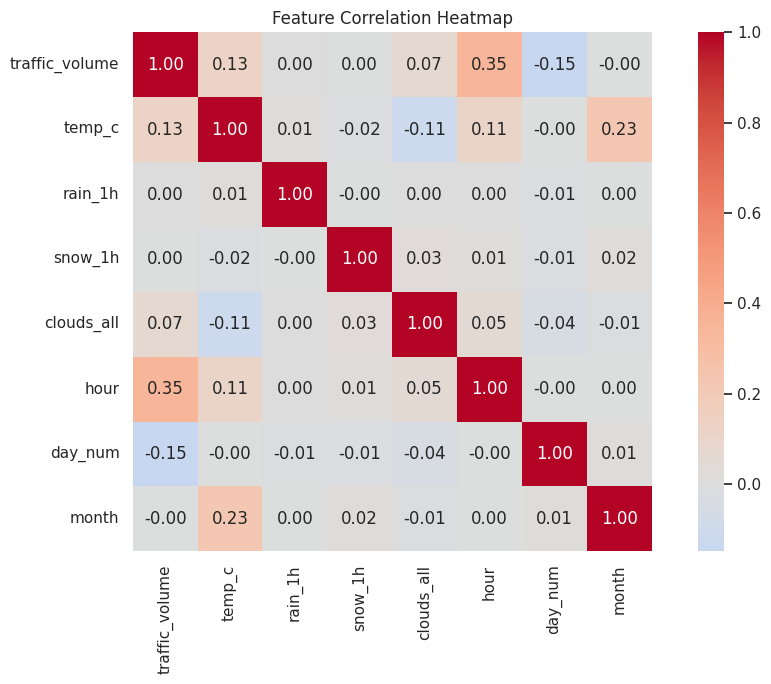

In [ ]:
corr_cols = [
    "traffic_volume",
    "temp_c",
    "rain_1h",
    "snow_1h",
    "clouds_all",
    "hour",
    "day_num",
    "month"
]

corr_table = df[corr_cols].corr()

display(corr_table.round(3))

plt.figure(figsize=(10, 7))
sns.heatmap(
    corr_table,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()


## 5. Seaborn pair plot

A sample of 1,500 is used


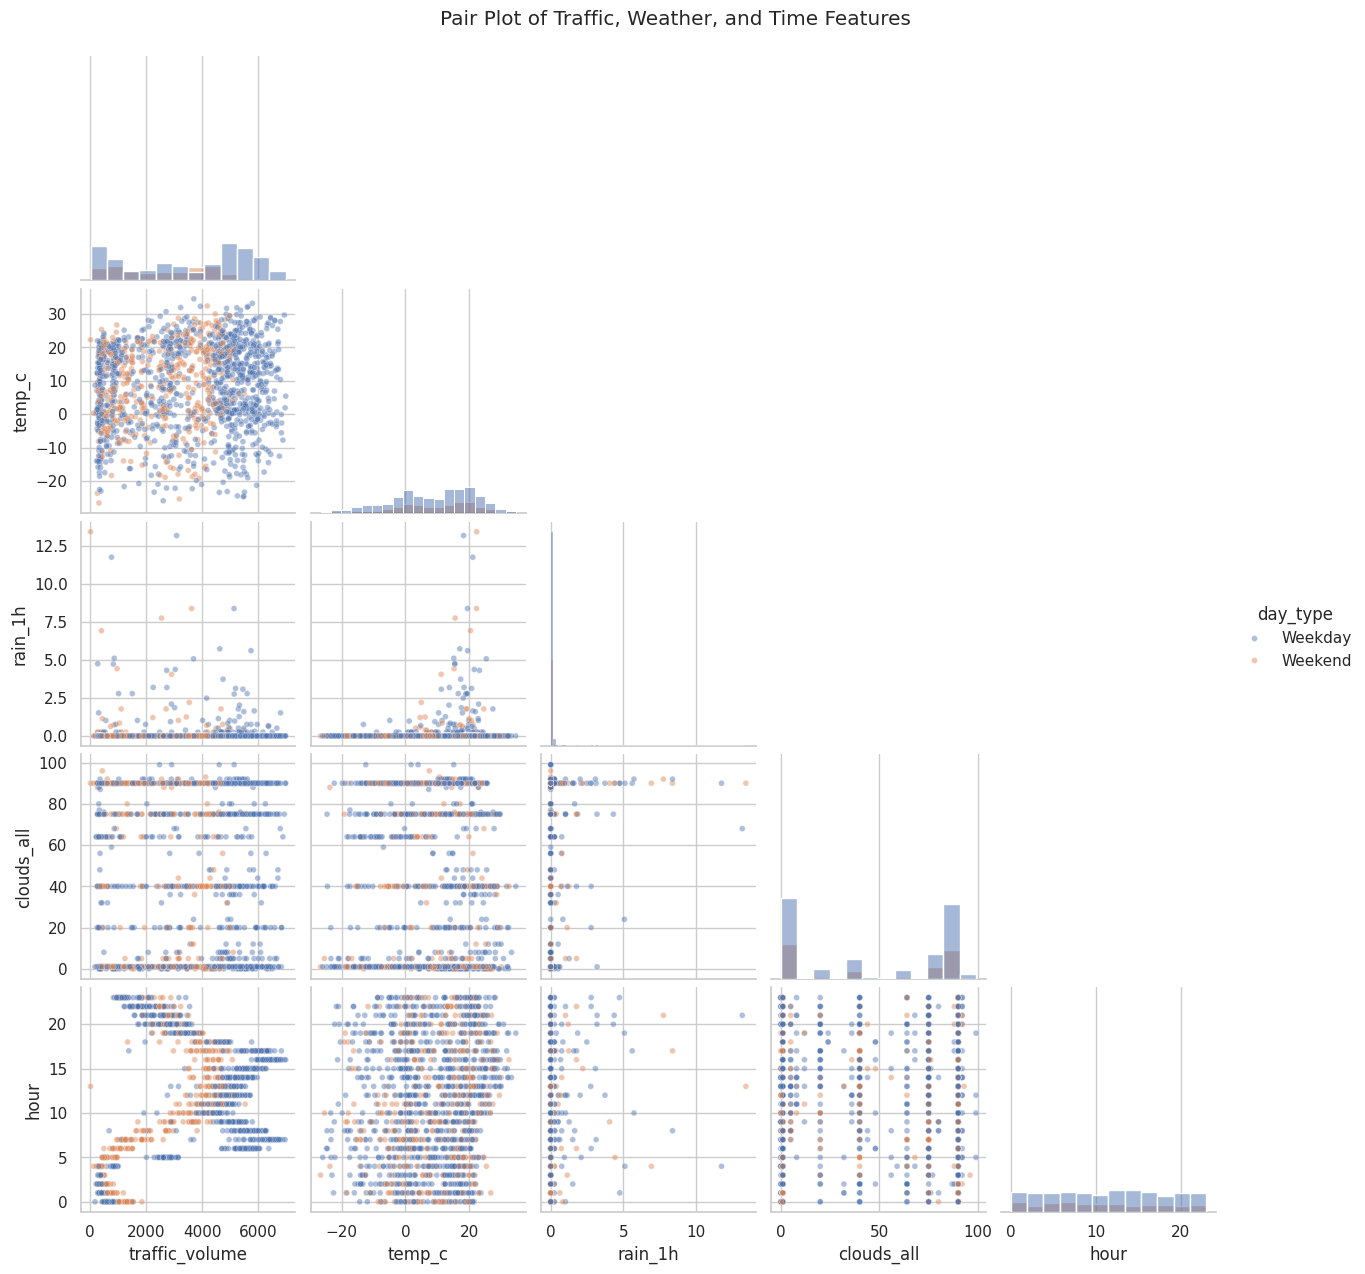

In [ ]:
pair_sample = df[
    [
        "traffic_volume",
        "temp_c",
        "rain_1h",
        "clouds_all",
        "hour",
        "day_type"
    ]
].sample(
    n=min(1500, len(df)),
    random_state=454
)

g = sns.pairplot(
    pair_sample,
    vars=[
        "traffic_volume",
        "temp_c",
        "rain_1h",
        "clouds_all",
        "hour"
    ],
    hue="day_type",
    corner=True,
    diag_kind="hist",
    plot_kws={"alpha": 0.45, "s": 18}
)

g.fig.suptitle(
    "Pair Plot of Traffic, Weather, and Time Features",
    y=1.02
)
plt.show()


# Exploratory visualizations




## 6. Average traffic by hour

This explores daily traffic patterns and compares weekdays with weekends.


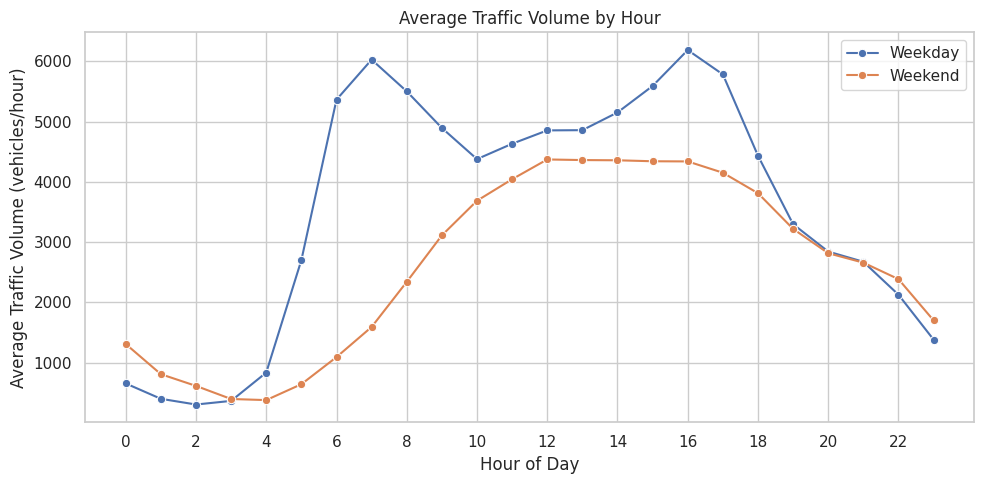

In [ ]:
hourly = (
    df.groupby(
        ["hour", "day_type"],
        as_index=False
    )["traffic_volume"]
    .mean()
)

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=hourly,
    x="hour",
    y="traffic_volume",
    hue="day_type",
    marker="o"
)

plt.title("Average Traffic Volume by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Traffic Volume (vehicles/hour)")
plt.xticks(range(0, 24, 2))
plt.legend(title="")
plt.tight_layout()
plt.show()


## 7. Average traffic by weather category

The categories are sorted by average traffic volume.


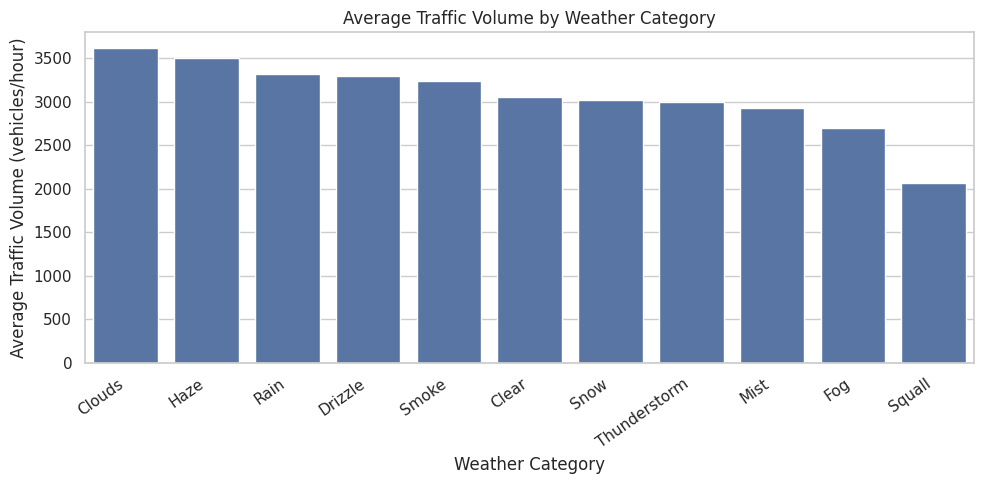

In [ ]:
weather_avg = (
    df.groupby(
        "weather_main",
        as_index=False
    )["traffic_volume"]
    .mean()
    .sort_values(
        "traffic_volume",
        ascending=False
    )
)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=weather_avg,
    x="weather_main",
    y="traffic_volume"
)

plt.title("Average Traffic Volume by Weather Category")
plt.xlabel("Weather Category")
plt.ylabel("Average Traffic Volume (vehicles/hour)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


## 8. Overall traffic-volume distribution


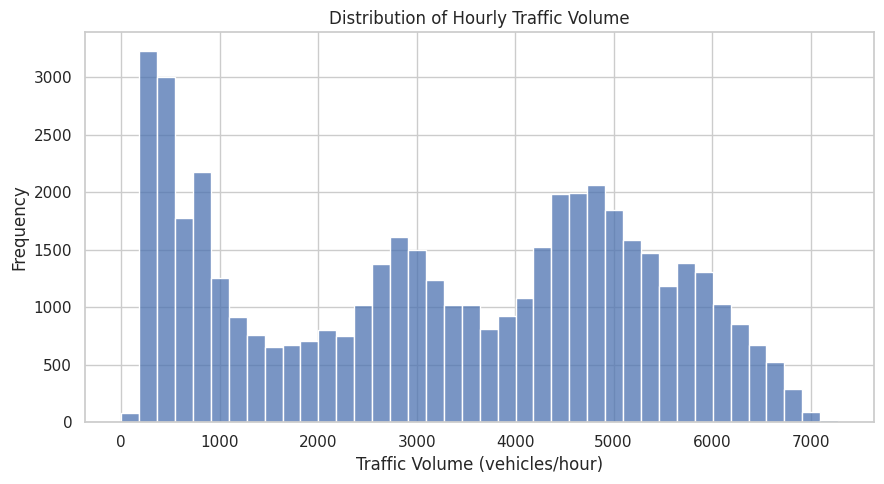

In [ ]:
plt.figure(figsize=(9, 5))
sns.histplot(
    data=df,
    x="traffic_volume",
    bins=40
)

plt.title("Distribution of Hourly Traffic Volume")
plt.xlabel("Traffic Volume (vehicles/hour)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


## 9. Traffic by day of week




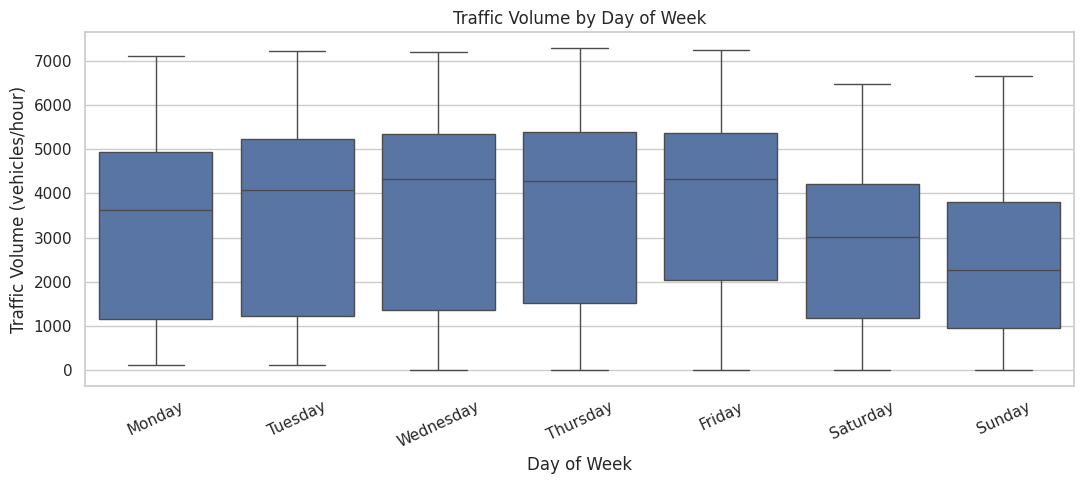

In [ ]:
day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

plt.figure(figsize=(11, 5))
sns.boxplot(
    data=df,
    x="day_name",
    y="traffic_volume",
    order=day_order,
    showfliers=False
)

plt.title("Traffic Volume by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Traffic Volume (vehicles/hour)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


## 10. Traffic under common weather conditions

The five most frequent weather categories are used to keep the comparison readable.


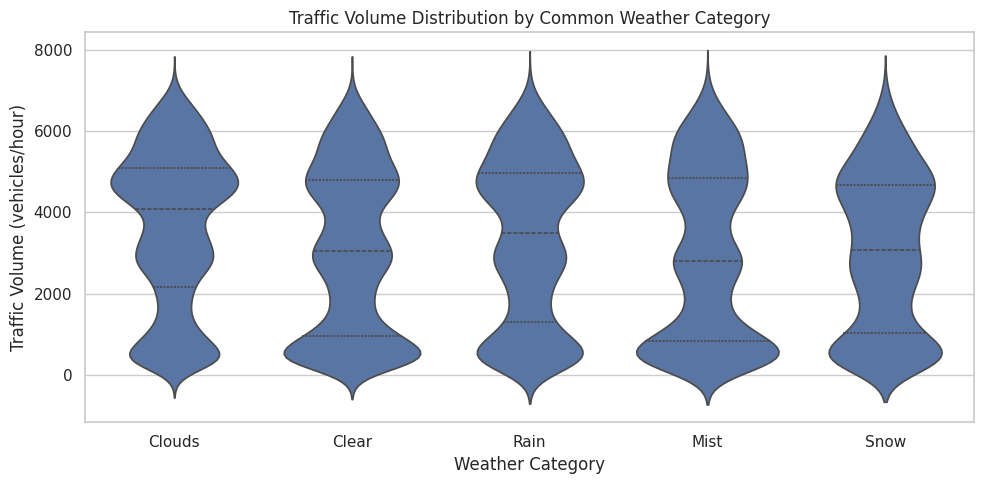

In [ ]:
top_weather = (
    df["weather_main"]
    .value_counts()
    .head(5)
    .index
)

violin_df = df[
    df["weather_main"].isin(top_weather)
]

plt.figure(figsize=(10, 5))
sns.violinplot(
    data=violin_df,
    x="weather_main",
    y="traffic_volume",
    inner="quartile"
)

plt.title("Traffic Volume Distribution by Common Weather Category")
plt.xlabel("Weather Category")
plt.ylabel("Traffic Volume (vehicles/hour)")
plt.tight_layout()
plt.show()


## 11. Weekday vs. weekend traffic

The KDE plot compares the smoothed distributions rather than only summary statistics.


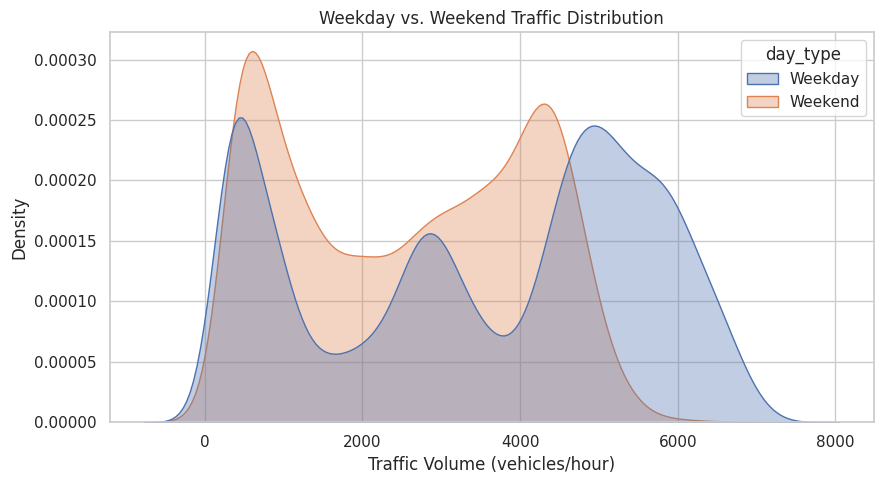

In [ ]:
plt.figure(figsize=(9, 5))
sns.kdeplot(
    data=df,
    x="traffic_volume",
    hue="day_type",
    fill=True,
    common_norm=False,
    alpha=0.35
)

plt.title("Weekday vs. Weekend Traffic Distribution")
plt.xlabel("Traffic Volume (vehicles/hour)")
plt.ylabel("Density")
plt.tight_layout()
plt.show()


## 12. Scatter plot — relationship among four features

This plot explicitly shows a relationship among:

- **Temperature**
- **Traffic volume**
- **Rush period** → color coded
- **Cloud cover** → point size



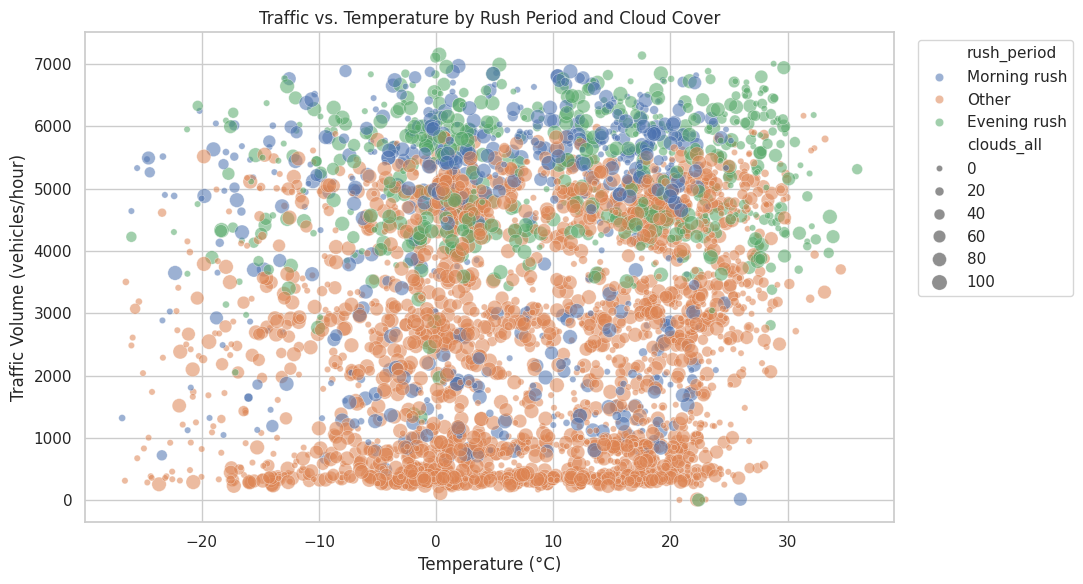

In [ ]:
scatter_sample = df.sample(
    n=min(3500, len(df)),
    random_state=454
)

plt.figure(figsize=(11, 6))
sns.scatterplot(
    data=scatter_sample,
    x="temp_c",
    y="traffic_volume",
    hue="rush_period",
    size="clouds_all",
    sizes=(20, 120),
    alpha=0.55
)

plt.title(
    "Traffic vs. Temperature by Rush Period and Cloud Cover"
)
plt.xlabel("Temperature (°C)")
plt.ylabel("Traffic Volume (vehicles/hour)")
plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()


# Interactive visualization




In [ ]:
weather_options = [
    "All"
] + sorted(
    df["weather_main"]
    .dropna()
    .unique()
    .tolist()
)

year_options = [
    "All"
] + sorted(
    df["year"]
    .unique()
    .tolist()
)

weather_widget = widgets.Dropdown(
    options=weather_options,
    value="All",
    description="Weather:"
)

year_widget = widgets.Dropdown(
    options=year_options,
    value="All",
    description="Year:"
)

hour_widget = widgets.IntRangeSlider(
    value=[0, 23],
    min=0,
    max=23,
    step=1,
    description="Hours:",
    continuous_update=False
)

@interact(
    weather=weather_widget,
    year=year_widget,
    hour_range=hour_widget
)
def interactive_traffic(
    weather,
    year,
    hour_range
):
    filtered = df[
        df["hour"].between(
            hour_range[0],
            hour_range[1]
        )
    ].copy()

    if weather != "All":
        filtered = filtered[
            filtered["weather_main"] == weather
        ]

    if year != "All":
        filtered = filtered[
            filtered["year"] == year
        ]

    if filtered.empty:
        print(
            "No observations match the selected filters."
        )
        return

    grouped = (
        filtered.groupby(
            "hour",
            as_index=False
        )["traffic_volume"]
        .mean()
    )

    plt.figure(figsize=(10, 5))
    sns.lineplot(
        data=grouped,
        x="hour",
        y="traffic_volume",
        marker="o"
    )

    plt.title(
        f"Interactive Average Traffic — "
        f"Weather: {weather}, Year: {year}"
    )
    plt.xlabel("Hour of Day")
    plt.ylabel(
        "Average Traffic Volume (vehicles/hour)"
    )
    plt.xticks(
        range(
            hour_range[0],
            hour_range[1] + 1
        )
    )
    plt.tight_layout()
    plt.show()


interactive(children=(Dropdown(description='Weather:', options=('All', 'Clear', 'Clouds', 'Drizzle', 'Fog', 'H…

# 13. Automatically calculated exploratory findings

These statements are computed from the cleaned dataset rather than manually typed, so they remain consistent with the actual data.


In [ ]:
# Peak average traffic hour
hour_summary = (
    df.groupby("hour")["traffic_volume"]
    .mean()
)

peak_hour = int(hour_summary.idxmax())
peak_hour_value = hour_summary.max()

# Weekday/weekend averages
day_type_summary = (
    df.groupby("day_type")["traffic_volume"]
    .mean()
    .sort_values(ascending=False)
)

# Weather category averages
weather_summary = (
    df.groupby("weather_main")["traffic_volume"]
    .mean()
    .sort_values(ascending=False)
)

# Strongest absolute linear correlation with traffic
traffic_corr_abs = (
    corr_table["traffic_volume"]
    .drop("traffic_volume")
    .abs()
    .sort_values(ascending=False)
)

strongest_feature = traffic_corr_abs.index[0]
strongest_r = corr_table.loc[
    strongest_feature,
    "traffic_volume"
]

print("KEY EXPLORATORY FINDINGS")

print(
    f"1. Peak average traffic occurs around "
    f"{peak_hour}:00 "
    f"({peak_hour_value:,.0f} vehicles/hour)."
)

print("\n2. Average traffic by day type:")
for label, value in day_type_summary.items():
    print(
        f"   {label}: "
        f"{value:,.0f} vehicles/hour"
    )

print(
    "\n3. Weather category with the highest "
    "average traffic:"
)
print(
    f"   {weather_summary.index[0]}: "
    f"{weather_summary.iloc[0]:,.0f} "
    "vehicles/hour"
)



KEY EXPLORATORY FINDINGS
1. Peak average traffic occurs around 16:00 (5,664 vehicles/hour).

2. Average traffic by day type:
   Weekday: 3,533 vehicles/hour
   Weekend: 2,572 vehicles/hour

3. Weather category with the highest average traffic:
   Clouds: 3,618 vehicles/hour
